# Import all the import lib

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Data load


In [2]:
df = pd.read_csv('Food_Delivery_Times.csv')

Data inspection

In [3]:
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [4]:
df.isnull().sum()

,0
Order_ID,0
Distance_km,0
Weather,30
Traffic_Level,30
Time_of_Day,30
Vehicle_Type,0
Preparation_Time_min,0
Courier_Experience_yrs,30
Delivery_Time_min,0


# Target columns distribution

Skewness= 0.5072511816152696


<Axes: xlabel='Delivery_Time_min', ylabel='Count'>

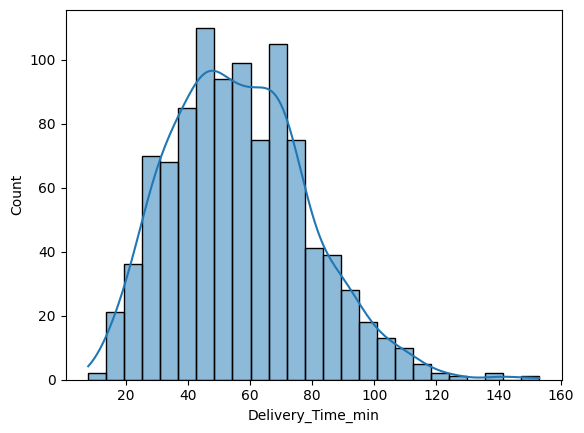

In [5]:
print("Skewness=",df['Delivery_Time_min'].skew())# check Skewness
sns.histplot(df['Delivery_Time_min'], kde=True)

<Axes: xlabel='Delivery_Time_min', ylabel='Count'>

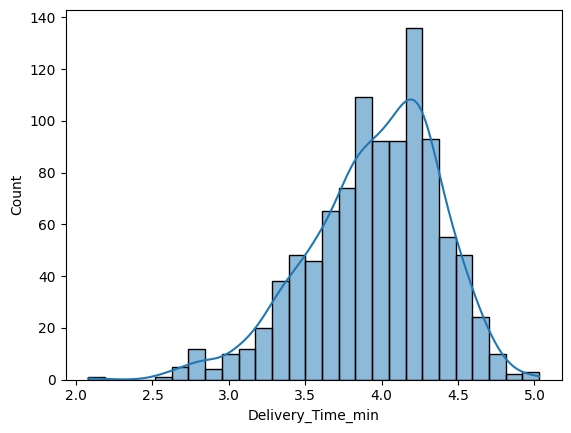

In [6]:
df['Delivery_Time_min'] = df['Delivery_Time_min'].apply(np.log)# use log for remove Skewness
sns.histplot(df['Delivery_Time_min'], kde = True)

In [7]:
df['Delivery_Time_min'].skew()

np.float64(-0.6215115869804703)

# Split columns  x and y

In [8]:
df.drop('Order_ID', axis = 1, inplace = True)
X = df.drop('Delivery_Time_min', axis=1)
y = df['Delivery_Time_min']

In [9]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Step 7: Preprocessing with Pipeline

### What is a Pipeline?
A pipeline is a **chain of steps** that run one after another.

> 🏭 **Real-life example:** A factory assembly line. Raw material enters → step 1 → step 2 → step 3 → finished product.

Our pipeline will do:
1. **Fill missing values** (Imputer)
2. **Convert text to numbers** (OneHotEncoder)
3. **Train the model**

### Why use a Pipeline?
| Without Pipeline | With Pipeline |
|---|---|
| Many separate cells for cleaning and encoding | One clean object |
| Test data can leak into preprocessing | No leakage |
| New data needs manual encoding | Just call `.predict()` |
| Hard to save and deploy | Save in one file |

### Define the column groups
Text columns and number columns need different treatment.

In [10]:
cat_cols = X_train.select_dtypes(include=['object', 'string']).columns.tolist()
num_cols = X_train.select_dtypes(include='number').columns.tolist()

print('Categorical:', cat_cols)
print('Numerical  :', num_cols)

Categorical: ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']
Numerical  : ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']


In one line: the Pipeline cleans a column in steps (fill, then convert), and the ColumnTransformer sends each column to the right Pipeline and joins the results.

### Build the preprocessor
- **Text columns:** fill missing with most frequent value → One-Hot Encode
- **Number columns:** fill missing with median

`ColumnTransformer` applies the right steps to the right columns.

`handle_unknown='ignore'` means: if a new category appears later, do not crash.

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer#ColumnTransformer is used when different columns need different preprocessing.
from sklearn.impute import SimpleImputer# SimpleImputer is used to handle missing values


In [12]:
from sklearn.preprocessing import OneHotEncoder#OneHotEncoder is a preprocessing technique in Machine Learning used to convert categorical data into numerical format(0,1).

In [13]:
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy = 'most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown = 'ignore'))
])

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy = 'median'))
])

preprocessor = ColumnTransformer([
    ('cat', cat_pipe, cat_cols),
    ('num', num_pipe, num_cols)
])
preprocessor

ColumnTransformer(transformers=[('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Weather', 'Traffic_Level', 'Time_of_Day',
                                  'Vehicle_Type']),
                                ('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median'))]),
                                 ['Distance_km', 'Preparation_Time_min',
                                  'Courier_Experience_yrs'])])

## Step 8: Decision Tree 🌳 (for comparison)

A Decision Tree asks Yes/No questions step by step.

> *Is distance > 10 km?* → Yes → *Is traffic high?* → Yes → predict 80 minutes.

It is easy to understand, but **one tree can overfit** (memorize the training data).

We put the preprocessor and the model together in one Pipeline.

In [14]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

dt_model = Pipeline([
    ('prep', preprocessor),
    ('model', DecisionTreeRegressor(max_depth= 5,random_state = 42))
])

dt_model.fit(X_train, y_train)


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Weather', 'Traffic_Level',
                                                   'Time_of_Day',
                                                   'Vehicle_Type']),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Distance_km',
                                                   'Preparation_Time_min',
                                                   'Courier_Experience_yrs'])])),
                ('model', DecisionTreeRegressor(max_depth=5, random_state=42))])

In [15]:
y_pred = dt_model.predict(X_test)

### Evaluate Decision Tree
We check **train and test** scores. If train is much higher than test, the model is overfitting.

In [16]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

print('Train score:', dt_model.score(X_train, y_train))
print('Test score :', dt_model.score(X_test, y_test))

Train score: 0.8252449379148517
Test score : 0.7480336641851977


## Step 9: Random Forest 🌲 (main model)

A Random Forest is **many decision trees working together**.

1. It builds many trees (here 100).
2. Each tree trains on a random sample of rows and columns.
3. Each tree makes its own prediction.
4. The forest **averages** all predictions.

> 💡 **Real-life example:** Ask 1 friend for movie advice → can be wrong. Ask 100 friends and take the average → much more reliable.

In [17]:
from sklearn.ensemble import RandomForestRegressor


from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

rf_model = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestRegressor(n_estimators= 101,random_state = 42))
])

rf_model.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Weather', 'Traffic_Level',
                                                   'Time_of_Day',
                                                   'Vehicle_Type']),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Distance_km',
                                                   'Preparation_Time_min',
                                                   'Courier_Experience_yrs'])])),
                ('model',
                 RandomForestRegressor(n_estimators=101, random_state=42))])

In [18]:
from sklearn.model_selection import RandomizedSearchCV

rf_params={
    "model__n_estimators":[100,200,300,400,500],
    "model__max_depth":[3,5,7,10,None],
    "model__min_samples_split":[1,3,5,7],
    "model__min_samples_leaf":['sqrt',0.5,1.0]

}

rf_search = RandomizedSearchCV(rf_model,rf_params,n_iter=20,cv=5,scoring='r2',random_state=52,n_jobs=-1)

rf_search.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('prep',
                                              ColumnTransformer(transformers=[('cat',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='most_frequent')),
                                                                                               ('encoder',
                                                                                                OneHotEncoder(handle_unknown='ignore'))]),
                                                                               ['Weather',
                                                                                'Traffic_Level',
                                                                                'Time_of_Day',
                                                                                'Vehicle_Type']),
                                                                              ('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['Di...
                                                                                'Preparation_Time_min',
                                                                                'Courier_Experience_yrs'])])),
                                             ('model',
                                              RandomForestRegressor(n_estimators=101,
                                                                    random_state=42))]),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'model__max_depth': [3, 5, 7, 10, None],
                                        'model__min_samples_leaf': ['sqrt', 0.5,
                                                                    1.0],
                                        'model__min_samples_split': [1, 3, 5,
                                                                     7],
                                        'model__n_estimators': [100, 200, 300,
                                                                400, 500]},
                   random_state=52, scoring='r2')

In [23]:

print("Best R2 score:", rf_search.best_score_)

Best R2 score: -0.010248617040528573


### Evaluate Random Forest

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor

# Redefine columns in case they were lost
cat_cols = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']
num_cols = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']

# Redefine the pipelines and preprocessor
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

preprocessor = ColumnTransformer([
    ('cat', cat_pipe, cat_cols),
    ('num', num_pipe, num_cols)
])

# Fit the Random Forest pipeline
rf_model = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestRegressor(n_estimators=100, random_state=42))
])

rf_model.fit(X_train, y_train)

# Evaluate Random Forest
print('Random Forest Train score:', rf_model.score(X_train, y_train))
print('Random Forest Test score :', rf_model.score(X_test, y_test))

Random Forest Train score: 0.9710261867913488
Random Forest Test score : 0.8481119881826331


### See predictions side by side
First 10 test orders: actual time vs what each model predicted.

In [21]:
# Get predictions from both models
dt_preds_log = dt_model.predict(X_test)
rf_preds_log = rf_model.predict(X_test)

# Convert log-transformed targets and predictions back to actual minutes
actual_minutes = np.exp(y_test.head(10).values)
dt_preds_minutes = np.exp(dt_preds_log[:10])
rf_preds_minutes = np.exp(rf_preds_log[:10])

# Create a comparison DataFrame
comparison_df = pd.DataFrame({
    'Actual Time (min)': np.round(actual_minutes, 1),
    'Decision Tree Prediction (min)': np.round(dt_preds_minutes, 1),
    'Random Forest Prediction (min)': np.round(rf_preds_minutes, 1)
})

comparison_df

,Actual Time (min),Decision Tree Prediction (min),Random Forest Prediction (min)
0,32.0,39.6,32.8
1,68.0,71.9,64.1
2,39.0,37.2,38.0
3,44.0,44.0,44.9
4,85.0,74.3,79.2
5,31.0,36.7,32.7
6,77.0,65.2,66.5
7,33.0,28.3,33.1
8,90.0,28.3,32.6
9,91.0,77.9,78.8


## Step 12: Predict a new order (the Pipeline advantage 🎉)

We give **raw data** directly. No manual encoding, no manual filling of missing values. The pipeline does everything.

In [22]:
# Define a brand new raw order
new_order = pd.DataFrame([{
    'Distance_km': 8.5,
    'Weather': 'Rainy',
    'Traffic_Level': 'High',
    'Time_of_Day': 'Evening',
    'Vehicle_Type': 'Scooter',
    'Preparation_Time_min': 15,
    'Courier_Experience_yrs': None  # The pipeline will handle this missing value using the median
}])

# Predict using the fitted Random Forest pipeline (which returns log-transformed minutes)
predicted_log_time = rf_model.predict(new_order)[0]

# Exponential transform to get the delivery time in actual minutes
predicted_time = np.exp(predicted_log_time)

print(f"Predicted delivery time for the new order: {predicted_time:.1f} minutes")

Predicted delivery time for the new order: 51.9 minutes


### Save the model
The whole pipeline (cleaning + encoding + model) is saved in **one file**. You can load it later, for example in a FastAPI app.